# **Import dataset**

In [7]:
import pandas as pd

df_topical = pd.read_stata("nsch_2024e_topical.dta")

# **Preproccessing Steps**

### Step 1: Understand the dataset
Check the dataset dimensions and data types to understand its overall structure.

In [8]:
print("Table dimension:", df_topical.shape)
print("-----------------------------------------")
print(df_topical.dtypes)


Table dimension: (51375, 457)
-----------------------------------------
height      float64
fipsst         int8
stratum         str
hhid          int32
formtype        str
             ...   
fpl_i3        int16
fpl_i4        int16
fpl_i5        int16
fpl_i6        int16
fwc         float64
Length: 457, dtype: object


Generate descriptive statistics for the dataset to obtain an initial overview of the variables and their distributions.

In [9]:
df_topical.describe(include="all")


,height,fipsst,stratum,hhid,formtype,totkids_r,tenure,hhlanguage,sc_age_years,sc_sex,...,hhcount_if,higrade,higrade_tvis,fpl_i1,fpl_i2,fpl_i3,fpl_i4,fpl_i5,fpl_i6,fwc
count,36235.000000,51375.000000,51375,5.137500e+04,51375,51375.000000,51375.000000,51120.000000,51375.000000,51375.000000,...,51375.000000,51375.000000,51375.000000,51375.000000,51375.000000,51375.000000,51375.000000,51375.000000,51375.000000,51375.000000
unique,NaN,NaN,2,NaN,3,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,1,NaN,T3,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,48401,NaN,21960,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,153.360485,28.138083,NaN,2.418752e+07,NaN,1.811835,1.450920,1.124883,9.665499,1.486637,...,0.027543,2.828613,3.488136,296.234083,296.037664,295.288370,296.431669,296.007591,295.210219,1411.265682
std,19.894039,16.211592,NaN,1.082975e+05,NaN,0.854730,0.780325,0.432514,5.211370,0.499826,...,0.163660,0.440175,0.802735,123.449750,123.487441,123.772403,123.333914,123.505593,123.866250,2421.255016
min,103.930000,1.000000,NaN,2.400002e+07,NaN,1.000000,1.000000,1.000000,0.000000,1.000000,...,0.000000,1.000000,1.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,12.335145
25%,137.160000,13.000000,NaN,2.409384e+07,NaN,1.000000,1.000000,1.000000,5.000000,1.000000,...,0.000000,3.000000,3.000000,196.000000,195.000000,193.000000,196.000000,195.000000,192.000000,323.873253
50%,157.480000,27.000000,NaN,2.418790e+07,NaN,2.000000,1.000000,1.000000,10.000000,1.000000,...,0.000000,3.000000,4.000000,368.000000,367.000000,364.000000,369.000000,366.000000,363.000000,723.611528
75%,167.640000,42.000000,NaN,2.428151e+07,NaN,2.000000,2.000000,1.000000,14.000000,2.000000,...,0.000000,3.000000,4.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,1522.186675


In [10]:
df_topical.head(10)  # Display top 10 records in the topical dataset


,height,fipsst,stratum,hhid,formtype,totkids_r,tenure,hhlanguage,sc_age_years,sc_sex,...,hhcount_if,higrade,higrade_tvis,fpl_i1,fpl_i2,fpl_i3,fpl_i4,fpl_i5,fpl_i6,fwc
0,NaN,48,1,24000016,T3,3,2,1.0,12,2,...,0,3,4,400,400,400,400,400,400,14108.624367
1,NaN,48,1,24000017,T1,1,2,1.0,5,2,...,0,3,4,400,400,400,400,400,400,7995.775609
2,NaN,47,1,24000044,T1,2,1,1.0,5,1,...,0,3,4,400,400,400,400,239,195,1593.130507
3,NaN,13,2A,24000054,T1,2,2,1.0,2,2,...,0,3,4,400,400,400,400,400,400,4395.677115
4,NaN,39,1,24000057,T1,2,1,1.0,2,2,...,0,3,4,400,400,400,400,400,400,1384.962653
5,NaN,19,1,24000071,T1,1,1,1.0,2,2,...,0,3,4,400,400,400,400,400,400,437.706177
6,NaN,31,2A,24000074,T1,1,1,1.0,1,2,...,0,3,4,286,400,254,400,55,339,1058.666318
7,137.16000,47,1,24000081,T2,2,3,2.0,7,2,...,0,3,4,400,400,400,400,400,400,1763.619834
8,175.25999,31,1,24000088,T3,1,1,1.0,17,1,...,0,3,4,400,400,400,400,400,400,109.931073
9,139.70000,27,2A,24000089,T2,1,1,1.0,9,2,...,0,3,4,400,400,400,400,400,400,948.037623


In [11]:
df_topical["formtype"].value_counts(dropna=False) # "dropna=False" mean To count and display the missing value or NaN


formtype
T3    21960
T2    15574
T1    13841
Name: count, dtype: int64

### Step 2: Choosing candidate variables & Handling missingness
(These are not the final chosen variables yet)

#### Research Question:
*   "What **health, lifestyle, and environmental patterns** are associated with children's screen-time levels?"

<br> Candidate variables are selected based on their **relevance** to the **research question** and grouped into four domains:
- General characteristics of the child
- Health
- Lifestyle
- Environmental factors





In [12]:
candidate_general = [
    "sc_age_years",   # Child's age (years)
    "sc_sex",         # Child's gender
    "family_r"        # Family structure
]

candidate_health = [
    "blindness",    # Blindness or serious vision difficulty
    "eyedoctor",    # Whether the child has seen an eye doctor
    "k4q22_r",      # Mental health professional treatment/need
    "k4q23"         # Medication due to emotional/concentration/behavior difficulties
]

candidate_lifestyle = [
    "screentime",   
    "hoursleep",    # hour sleep for T2,T3
    "hoursleep05",  # hour sleep for T1
    "physactiv",    # Exercise, Play Sport, or Physical Activity for 60 Minutes
    "k6q71_r"       # Interest/curiosity in learning
]

candidate_environmet = [
    "higrade",      # Adult education
    "foodsit",      # Household food affordability
    "k10q12",       # Park/playground
    "k10q13",       # Recreation/community center
    "k10q14"        # Library/bookmobile
]


Checking the number of missing values

In [13]:
def missing_summary(df, variables):
    return (
        pd.DataFrame({
            "Missing Count": df[variables].isna().sum(),
            "Missing Percentage": (
                df[variables].isna().mean() * 100
            ).round(2)
        })
        .sort_values("Missing Count", ascending=False)
    )


all_candidate_vars = (
    candidate_general
    + candidate_health
    + candidate_lifestyle
    + candidate_environmet
)

missing = missing_summary(df_topical, all_candidate_vars)

print(missing)


              Missing Count  Missing Percentage
hoursleep05           37666               73.32
physactiv             14349               27.93
hoursleep             14336               27.90
k10q13                 1404                2.73
k10q14                 1402                2.73
k10q12                 1390                2.71
family_r               1328                2.58
foodsit                1253                2.44
k4q23                   959                1.87
screentime              868                1.69
k6q71_r                 628                1.22
eyedoctor               240                0.47
k4q22_r                 237                0.46
blindness               198                0.39
sc_age_years              0                0.00
sc_sex                    0                0.00
higrade                   0                0.00


The **top 3 most missing values** are


1.   `hoursleep05`: 37666 missing (73.32%)
2.   `physactiv`: 14349 missing (27.93%)
3.   `hoursleep`: 14336 missing (27.90%)

These high percentages are primarily due to variables being collected only for specific NSCH form types.

<br> Therefore, the missingness was examined by form type before deciding how to handle these variables.

<br> `hoursleep05` is collected for T1 respondents, while `hoursleep` is collected for T2 and T3 respondents. Therefore, these age-specific sleep variables were combined into `sleep_hours` variable.

In [14]:
def missing_by_group(df, variables, group_col):
    return (
        df.groupby(group_col)[variables]
        .apply(lambda group: group.isna().mean() * 100)
        .T
        .round(2)
    )


most_missing_vars = missing[missing["Missing Count"] > 1500].index.tolist()

print(missing_by_group(df_topical, most_missing_vars, "formtype"))


formtype         T1      T2      T3
hoursleep05    0.95  100.00  100.00
physactiv    100.00    1.23    1.44
hoursleep    100.00    1.25    1.37


In [15]:
df_topical["sleep_hours"] = df_topical["hoursleep"].fillna(
    df_topical["hoursleep05"]
)

missing_sleep_hours = missing_summary(
    df_topical,
    ["sleep_hours"]
)

print(missing_sleep_hours)


             Missing Count  Missing Percentage
sleep_hours            627                1.22


C:\Users\UsEr\AppData\Local\Temp\ipykernel_1376\3975313869.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_topical["sleep_hours"] = df_topical["hoursleep"].fillna(


`physactiv` is unavailable for all T1 respondents and is therefore structurally missing for the youngest age group.

<br> Since the analysis aims to include T1, T2, and T3 respondents, **this variable is excluded** from the candidate feature set rather than imputed.

<br> Therefore, `physactiv` is removed from the candidate variables list.

In [16]:
candidate_general = [
    "sc_age_years",
    "sc_sex",
    "family_r"          # Family structure
]

candidate_health = [
    "blindness",
    "eyedoctor",
    "k4q22_r",           # Mental health professional treatment/need
    "k4q23"              # Medication due to emotional/concentration/behavior difficulties
]

candidate_lifestyle = [
    "screentime",
    "sleep_hours",       # Unified sleep variable from hoursleep + hoursleep05
    "k6q71_r"            # Interest/curiosity in learning
]

candidate_environment = [
    "higrade",           # Adult education
    "foodsit",           # Household food affordability
    "k10q12",            # Park/playground
    "k10q13",            # Recreation/community center
    "k10q14"             # Library/bookmobile
]

all_candidate_vars = (
    candidate_general
    + candidate_health
    + candidate_lifestyle
    + candidate_environment
)


In [17]:
missing = missing_summary(df_topical, all_candidate_vars)

print(missing)


              Missing Count  Missing Percentage
k10q13                 1404                2.73
k10q14                 1402                2.73
k10q12                 1390                2.71
family_r               1328                2.58
foodsit                1253                2.44
k4q23                   959                1.87
screentime              868                1.69
k6q71_r                 628                1.22
sleep_hours             627                1.22
eyedoctor               240                0.47
k4q22_r                 237                0.46
blindness               198                0.39
sc_sex                    0                0.00
sc_age_years              0                0.00
higrade                   0                0.00


The major missingness has been addressed.

The remaining missing values were examined to determine whether they were reasonably distributed across T1, T2, and T3.

In [18]:
missing_by_form = missing_by_group(
    df_topical,
    all_candidate_vars,
    "formtype"
)

print(missing_by_form)


formtype        T1    T2    T3
sc_age_years  0.00  0.00  0.00
sc_sex        0.00  0.00  0.00
family_r      3.06  2.59  2.28
blindness     0.27  0.43  0.43
eyedoctor     0.39  0.42  0.55
k4q22_r       0.34  0.44  0.55
k4q23         2.70  1.66  1.48
screentime    2.12  1.44  1.60
sleep_hours   0.95  1.25  1.37
k6q71_r       1.54  1.05  1.15
higrade       0.00  0.00  0.00
foodsit       2.79  2.32  2.30
k10q12        3.03  2.52  2.64
k10q13        3.19  2.66  2.50
k10q14        3.07  2.66  2.56


Investigate further into each feature. Making sure NaN really represents missing responses and isn't hiding different types of nonresponse.

In [19]:
def value_counts_summary(df, variables):
    for var in variables:
        print(f"\n--- {var} ---")
        print(df[var].value_counts(dropna=False).sort_index())


value_counts_summary(df_topical, all_candidate_vars)



--- sc_age_years ---
sc_age_years
0     1537
1     1949
2     2870
3     2462
4     2489
5     2534
6     2203
7     2408
8     2563
9     2626
10    2860
11    2914
12    2923
13    3165
14    3459
15    3691
16    4288
17    4434
Name: count, dtype: int64

--- sc_sex ---
sc_sex
1    26374
2    25001
Name: count, dtype: int64

--- family_r ---
family_r
1.0    33780
2.0     1988
3.0     1998
4.0      693
5.0     7483
6.0     2376
7.0     1303
8.0      426
NaN     1328
Name: count, dtype: int64

--- blindness ---
blindness
1.0      732
2.0    50445
NaN      198
Name: count, dtype: int64

--- eyedoctor ---
eyedoctor
1.0    22599
2.0    28536
NaN      240
Name: count, dtype: int64

--- k4q22_r ---
k4q22_r
1.0     7220
2.0     1275
3.0    42643
NaN      237
Name: count, dtype: int64

--- k4q23 ---
k4q23
1.0     5355
2.0    45061
NaN      959
Name: count, dtype: int64

--- screentime ---
screentime
1.0     7257
2.0     7901
3.0    13596
4.0     9430
5.0    12323
NaN      868
Name: count, d

Most candidate variables are **categorical** or **ordinal**.

<br> Therefore, **mode imputation** is used to handle the remaining small amount of missing data.

The mode of each variable is calculated from its observed values and used to replace its missing values.

In [20]:
impute_vars = [
    var
    for var in all_candidate_vars
    if df_topical[var].isna().any()
]

print(impute_vars)


['family_r', 'blindness', 'eyedoctor', 'k4q22_r', 'k4q23', 'screentime', 'sleep_hours', 'k6q71_r', 'foodsit', 'k10q12', 'k10q13', 'k10q14']


In [21]:
for var in impute_vars:
    mode_value = df_topical[var].mode()[0]
    df_topical[var] = df_topical[var].fillna(mode_value)

print(df_topical[all_candidate_vars].isna().sum())


sc_age_years    0
sc_sex          0
family_r        0
blindness       0
eyedoctor       0
k4q22_r         0
k4q23           0
screentime      0
sleep_hours     0
k6q71_r         0
higrade         0
foodsit         0
k10q12          0
k10q13          0
k10q14          0
dtype: int64


### Step 3: Data Validation
Create a separate dataframe containing the selected candidate variables and verify that no missing values remain.

In [22]:
df_cluster = df_topical[all_candidate_vars].copy()

print(df_cluster.isna().sum())

sc_age_years    0
sc_sex          0
family_r        0
blindness       0
eyedoctor       0
k4q22_r         0
k4q23           0
screentime      0
sleep_hours     0
k6q71_r         0
higrade         0
foodsit         0
k10q12          0
k10q13          0
k10q14          0
dtype: int64


Check the data types of the selected variables

In [23]:
df_cluster.dtypes

sc_age_years       int8
sc_sex             int8
family_r        float64
blindness       float64
eyedoctor       float64
k4q22_r         float64
k4q23           float64
screentime      float64
sleep_hours     float64
k6q71_r         float64
higrade            int8
foodsit         float64
k10q12          float64
k10q13          float64
k10q14          float64
dtype: object

Check the observed values of each variable to identify any unexpected categories or invalid values.

In [24]:
value_counts_summary(df_cluster, all_candidate_vars)



--- sc_age_years ---
sc_age_years
0     1537
1     1949
2     2870
3     2462
4     2489
5     2534
6     2203
7     2408
8     2563
9     2626
10    2860
11    2914
12    2923
13    3165
14    3459
15    3691
16    4288
17    4434
Name: count, dtype: int64

--- sc_sex ---
sc_sex
1    26374
2    25001
Name: count, dtype: int64

--- family_r ---
family_r
1.0    35108
2.0     1988
3.0     1998
4.0      693
5.0     7483
6.0     2376
7.0     1303
8.0      426
Name: count, dtype: int64

--- blindness ---
blindness
1.0      732
2.0    50643
Name: count, dtype: int64

--- eyedoctor ---
eyedoctor
1.0    22599
2.0    28776
Name: count, dtype: int64

--- k4q22_r ---
k4q22_r
1.0     7220
2.0     1275
3.0    42880
Name: count, dtype: int64

--- k4q23 ---
k4q23
1.0     5355
2.0    46020
Name: count, dtype: int64

--- screentime ---
screentime
1.0     7257
2.0     7901
3.0    14464
4.0     9430
5.0    12323
Name: count, dtype: int64

--- sleep_hours ---
sleep_hours
1.0      439
2.0     1578
3.0    

# Exploratory Data Analysis (EDA)

### Step 4: Univariate EDA

After preprocessing, each selected variable is checked individually.

The summary method depends on the variable type.


In [25]:
numeric_vars = [
    "sc_age_years"
]

ordinal_vars = [
    "screentime",
    "sleep_hours",
    "k6q71_r",
    "higrade",
    "foodsit"
]

categorical_vars = [
    "sc_sex",
    "family_r",
    "blindness",
    "eyedoctor",
    "k4q22_r",
    "k4q23",
    "k10q12",
    "k10q13",
    "k10q14"
]

print("Numeric variables:", numeric_vars)
print("Ordinal variables:", ordinal_vars)
print("Categorical variables:", categorical_vars)


Numeric variables: ['sc_age_years']
Ordinal variables: ['screentime', 'sleep_hours', 'k6q71_r', 'higrade', 'foodsit']
Categorical variables: ['sc_sex', 'family_r', 'blindness', 'eyedoctor', 'k4q22_r', 'k4q23', 'k10q12', 'k10q13', 'k10q14']


#### Age Distribution

`sc_age_years` is numerical, so descriptive statistics and its distribution are checked.


In [45]:
df_cluster["sc_age_years"].describe()


count    51375.000000
mean         9.665499
std          5.211370
min          0.000000
25%          5.000000
50%         10.000000
75%         14.000000
max         17.000000
Name: sc_age_years, dtype: float64

In [47]:
age_counts = df_cluster["sc_age_years"].value_counts().sort_index()
print(age_counts)


sc_age_years
0     1537
1     1949
2     2870
3     2462
4     2489
5     2534
6     2203
7     2408
8     2563
9     2626
10    2860
11    2914
12    2923
13    3165
14    3459
15    3691
16    4288
17    4434
Name: count, dtype: int64


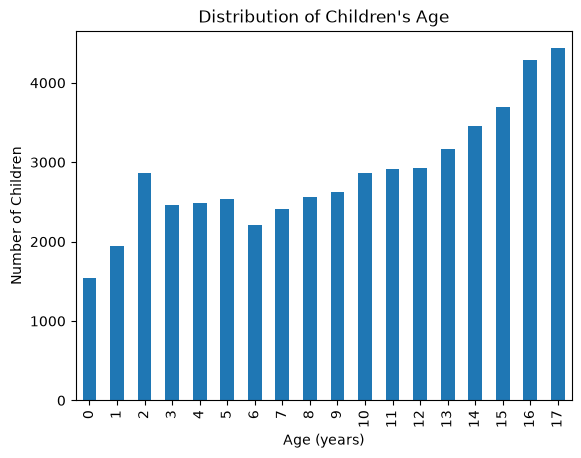

In [28]:
import matplotlib.pyplot as plt

age_counts.plot(kind="bar")
plt.xlabel("Age (years)")
plt.ylabel("Number of Children")
plt.title("Distribution of Children's Age")
plt.show()


The dataset covers ages 0–17. Older ages have more observations, so age should be considered in later comparisons.


#### Sleep Distribution

`sleep_hours` is kept as an ordered category because T1 and T2/T3 use different hour ranges for the same codes.


In [29]:
sleep_table = pd.DataFrame({
    "Count": df_cluster["sleep_hours"].value_counts().sort_index(),
    "Percentage": (
        df_cluster["sleep_hours"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

display(sleep_table)


,Count,Percentage
sleep_hours,,
1.0,439,0.85
2.0,1578,3.07
3.0,5960,11.60
4.0,15373,29.92
5.0,13799,26.86
6.0,8891,17.31
7.0,5335,10.38


Most observations are in the middle sleep categories. The codes should not be read as exact hours.


#### Screen Time Distribution

`screentime` is the main variable in this project.

1 = Less than 1 hour, 2 = 1 hour, 3 = 2 hours, 4 = 3 hours, 5 = 4 or more hours.


In [30]:
screen_labels = {
    1.0: "Less than 1 hour",
    2.0: "1 hour",
    3.0: "2 hours",
    4.0: "3 hours",
    5.0: "4 or more hours"
}

screen_counts = df_cluster["screentime"].value_counts().sort_index()
print(screen_counts)


screentime
1.0     7257
2.0     7901
3.0    14464
4.0     9430
5.0    12323
Name: count, dtype: int64


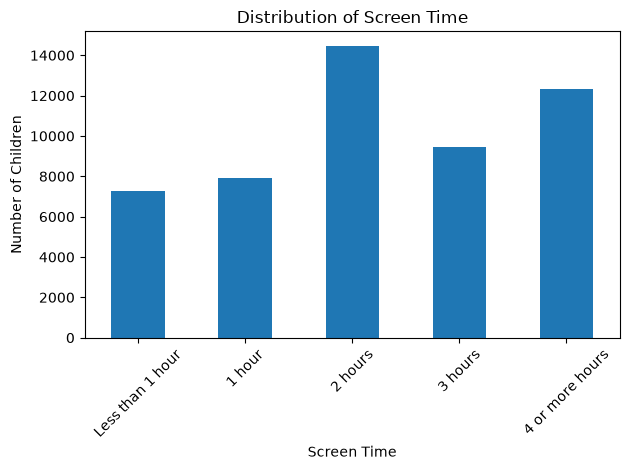

In [31]:
screen_plot = screen_counts.copy()
screen_plot.index = [screen_labels[x] for x in screen_plot.index]

screen_plot.plot(kind="bar")
plt.xlabel("Screen Time")
plt.ylabel("Number of Children")
plt.title("Distribution of Screen Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The most common category is 2 hours, followed by 4 or more hours. All categories have enough observations for comparison.


#### Other Variables

The remaining categorical and ordinal variables are checked using frequency and percentage tables.


In [32]:
from IPython.display import display

label_maps = {
    "sc_sex": {
        1: "Male",
        2: "Female"
    },
    "family_r": {
        1.0: "Two biological/adoptive parents, married",
        2.0: "Two biological/adoptive parents, not married",
        3.0: "Two parents, at least one not biological/adoptive, married",
        4.0: "Two parents, at least one not biological/adoptive, not married",
        5.0: "Single mother",
        6.0: "Single father",
        7.0: "Grandparent household",
        8.0: "Other relation"
    },
    "blindness": {
        1.0: "Yes",
        2.0: "No"
    },
    "eyedoctor": {
        1.0: "Yes",
        2.0: "No"
    },
    "k4q22_r": {
        1.0: "Received treatment",
        2.0: "No treatment, but needed it",
        3.0: "No treatment, did not need it"
    },
    "k4q23": {
        1.0: "Yes",
        2.0: "No"
    },
    "k6q71_r": {
        1.0: "Always",
        2.0: "Usually",
        3.0: "Sometimes",
        4.0: "Never"
    },
    "higrade": {
        1: "Less than high school",
        2: "High school",
        3: "More than high school"
    },
    "foodsit": {
        1.0: "Always afford good nutritious meals",
        2.0: "Enough food, but not always the kinds we should eat",
        3.0: "Sometimes could not afford enough",
        4.0: "Often could not afford enough"
    },
    "k10q12": {
        1.0: "Yes",
        2.0: "No"
    },
    "k10q13": {
        1.0: "Yes",
        2.0: "No"
    },
    "k10q14": {
        1.0: "Yes",
        2.0: "No"
    }
}

def frequency_table(df, var):
    counts = df[var].value_counts().sort_index()

    table = pd.DataFrame({
        "Count": counts,
        "Percentage": (counts / len(df) * 100).round(2)
    })

    if var in label_maps:
        table.index = [
            label_maps[var].get(x, str(x))
            for x in table.index
        ]

    return table

other_vars = [
    "sc_sex",
    "family_r",
    "blindness",
    "eyedoctor",
    "k4q22_r",
    "k4q23",
    "k6q71_r",
    "higrade",
    "foodsit",
    "k10q12",
    "k10q13",
    "k10q14"
]

for var in other_vars:
    print(f"\n--- {var} ---")
    display(frequency_table(df_cluster, var))



--- sc_sex ---


,Count,Percentage
Male,26374,51.34
Female,25001,48.66



--- family_r ---


,Count,Percentage
"Two biological/adoptive parents, married",35108,68.34
"Two biological/adoptive parents, not married",1988,3.87
"Two parents, at least one not biological/adoptive, married",1998,3.89
"Two parents, at least one not biological/adoptive, not married",693,1.35
Single mother,7483,14.57
Single father,2376,4.62
Grandparent household,1303,2.54
Other relation,426,0.83



--- blindness ---


...

,Count,Percentage
Yes,39353,76.6
No,12022,23.4



--- k10q13 ---


,Count,Percentage
Yes,24231,47.16
No,27144,52.84



--- k10q14 ---


,Count,Percentage
Yes,34901,67.93
No,16474,32.07


`blindness` is highly imbalanced, and some variables have rare categories. They are kept for now and reviewed again in Step 7.


### Step 5: Screen-Time-Focused EDA

`screentime` is compared with the other candidate variables using row percentages.

These results show association only, not causation.


In [48]:
def screen_time_percent_table(df, group_var):
    table = pd.crosstab(
        df[group_var],
        df["screentime"],
        normalize="index"
    ) * 100

    table = table.reindex(
        columns=[1.0, 2.0, 3.0, 4.0, 5.0],
        fill_value=0
    )

    table.columns = [screen_labels[x] for x in table.columns]

    if group_var in label_maps:
        table.index = [
            label_maps[group_var].get(x, str(x))
            for x in table.index
        ]

    return table.round(1)


#### Age vs Screen Time


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
sc_age_years,,,,,
0,82.2,6.3,8.5,1.8,1.2
1,54.0,20.1,16.0,5.5,4.4
2,32.8,25.2,26.2,9.2,6.6
3,23.7,28.3,30.7,11.3,5.9
4,20.0,28.2,33.6,11.1,7.1
5,18.8,27.9,32.8,12.3,8.2
6,14.8,24.9,33.0,14.7,12.7
7,13.0,22.3,34.4,16.8,13.6
8,12.4,19.2,35.6,16.9,15.9


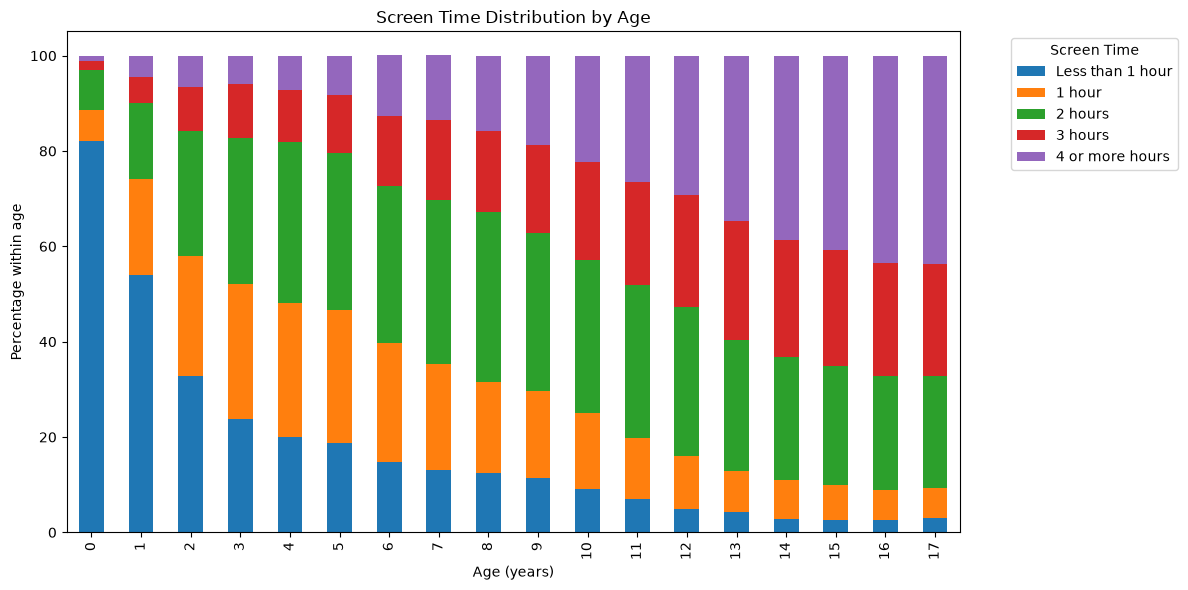

In [34]:
age_screen = screen_time_percent_table(df_cluster, "sc_age_years")
display(age_screen)

age_screen.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.xlabel("Age (years)")
plt.ylabel("Percentage within age")
plt.title("Screen Time Distribution by Age")
plt.legend(
    title="Screen Time",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


Higher screen-time categories become more common among older children. Age looks useful for this project.


#### Sex


In [35]:
display(
    screen_time_percent_table(
        df_cluster,
        "sc_sex"
    )
)


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Male,13.8,15.0,27.7,18.5,25.0
Female,14.5,15.8,28.6,18.2,22.9


The screen-time percentages are quite similar between male and female children.


#### Family


In [36]:
display(
    screen_time_percent_table(
        df_cluster,
        "family_r"
    )
)


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
"Two biological/adoptive parents, married",16.7,16.9,28.7,17.3,20.4
"Two biological/adoptive parents, not married",15.4,16.1,27.9,18.4,22.2
"Two parents, at least one not biological/adoptive, married",4.8,9.0,24.4,21.1,40.7
"Two parents, at least one not biological/adoptive, not married",5.2,10.4,27.6,21.4,35.5
Single mother,8.5,12.4,26.5,21.0,31.5
Single father,7.7,12.2,29.7,20.2,30.2
Grandparent household,6.5,9.2,26.5,21.9,35.9
Other relation,12.2,10.6,26.8,18.8,31.7


Family groups show some differences in screen time, but a few groups are small.


#### Health Variables


In [37]:
health_vars = [
    "blindness",
    "eyedoctor",
    "k4q22_r",
    "k4q23"
]

for var in health_vars:
    print(f"\n--- Screen time by {var} (%) ---")
    display(
        screen_time_percent_table(
            df_cluster,
            var
        )
    )



--- Screen time by blindness (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,8.6,10.5,22.7,18.2,40.0
No,14.2,15.4,28.2,18.4,23.8



--- Screen time by eyedoctor (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,7.8,12.6,28.0,20.9,30.7
No,19.1,17.6,28.3,16.4,18.7



--- Screen time by k4q22_r (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Received treatment,5.6,9.4,24.0,21.9,39.1
"No treatment, but needed it",6.3,8.0,24.2,20.0,41.6
"No treatment, did not need it",15.8,16.6,29.0,17.7,20.9



--- Screen time by k4q23 (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,3.9,8.6,23.1,22.7,41.7
No,15.3,16.2,28.7,17.9,21.9


`k4q22_r` and `k4q23` show noticeable differences. `blindness` should be read carefully because the Yes group is small.


#### Sleep


In [38]:
display(
    screen_time_percent_table(
        df_cluster,
        "sleep_hours"
    )
)


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
sleep_hours,,,,,
1.0,8.2,6.4,15.5,11.8,58.1
2.0,5.0,5.8,20.5,21.7,47.0
3.0,4.6,9.3,26.7,23.7,35.6
4.0,5.5,11.8,31.5,21.7,29.4
5.0,11.5,17.2,30.6,19.4,21.2
6.0,20.7,22.4,28.0,14.0,14.9
7.0,48.5,19.6,17.2,6.6,8.1


Screen time changes across sleep categories, but the sleep codes are not exact hours.


#### Curiosity vs Screen Time


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Always,19.3,18.6,30.0,15.7,16.4
Usually,9.6,13.5,28.8,21.6,26.6
Sometimes,4.5,7.2,19.8,21.2,47.2
Never,7.8,7.0,13.2,16.7,55.3


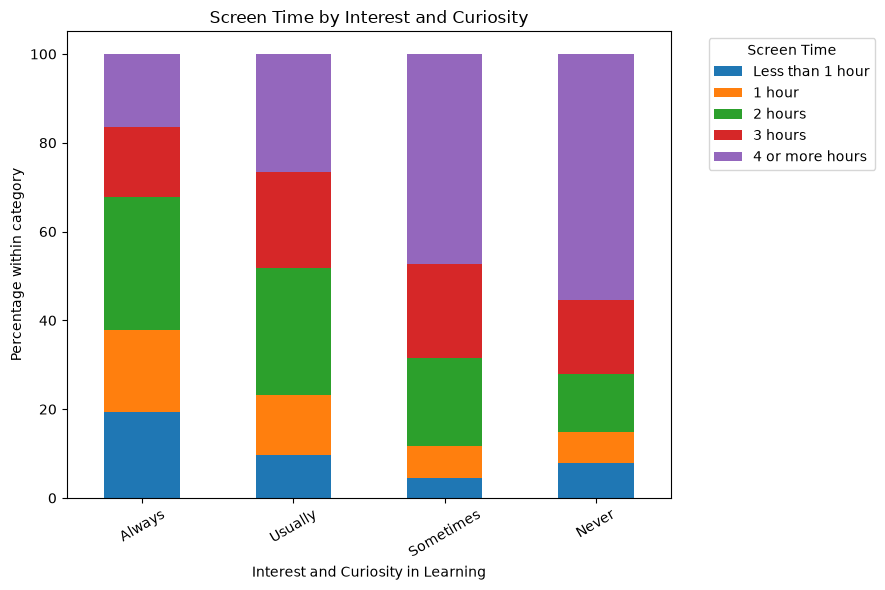

In [54]:
curiosity_screen = screen_time_percent_table(
    df_cluster,
    "k6q71_r"
)

display(curiosity_screen)

curiosity_screen.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6)
)

plt.xlabel("Interest and Curiosity in Learning")
plt.ylabel("Percentage within category")
plt.title("Screen Time by Interest and Curiosity")
plt.legend(
    title="Screen Time",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


Higher screen-time categories become more common as interest and curiosity are reported less often.


#### Education


In [40]:
display(
    screen_time_percent_table(
        df_cluster,
        "higrade"
    )
)


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Less than high school,15.3,11.0,27.8,18.2,27.7
High school,9.2,12.3,29.1,20.2,29.1
More than high school,14.8,15.9,28.0,18.1,23.2


Education level shows some differences, but one category is much more common than the others.


#### Food Situation vs Screen Time


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Always afford good nutritious meals,16.3,16.5,28.9,17.3,21.0
"Enough food, but not always the kinds we should eat",8.9,12.8,26.9,21.1,30.3
Sometimes could not afford enough,7.9,11.1,24.0,20.5,36.6
Often could not afford enough,9.7,11.8,17.2,17.2,44.1


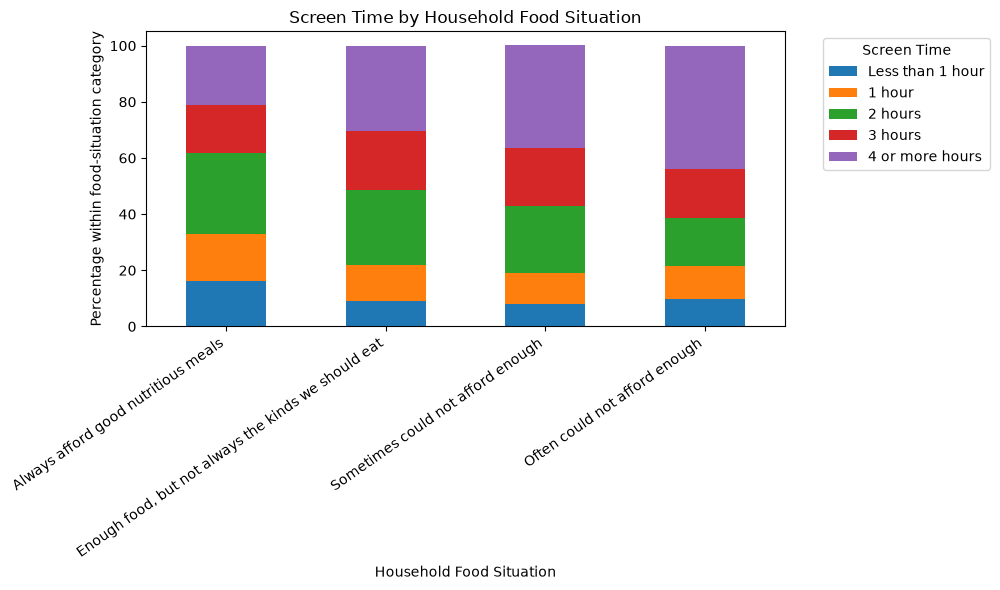

In [41]:
food_screen = screen_time_percent_table(
    df_cluster,
    "foodsit"
)

display(food_screen)

food_screen.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel("Household Food Situation")
plt.ylabel("Percentage within food-situation category")
plt.title("Screen Time by Household Food Situation")
plt.legend(
    title="Screen Time",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


Higher screen-time categories are more common in households with more difficulty affording food.


#### Neighborhood Variables


In [42]:
neighborhood_vars = [
    "k10q12",
    "k10q13",
    "k10q14"
]

for var in neighborhood_vars:
    print(f"\n--- Screen time by {var} (%) ---")
    display(
        screen_time_percent_table(
            df_cluster,
            var
        )
    )



--- Screen time by k10q12 (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,14.8,15.7,28.6,18.0,23.0
No,12.1,14.4,26.9,19.6,27.1



--- Screen time by k10q13 (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,14.7,16.1,27.2,18.3,23.6
No,13.6,14.7,29.0,18.4,24.3



--- Screen time by k10q14 (%) ---


,Less than 1 hour,1 hour,2 hours,3 hours,4 or more hours
Yes,14.5,15.7,28.8,18.1,22.9
No,13.3,14.8,26.8,18.9,26.2


The neighborhood variables show smaller differences than several other variables. `k10q13` shows especially little change.


### Step 6: Relationship Analysis

Some variables may contain similar information.

Selected crosstabs are used because most variables are categorical or ordinal.


In [43]:
def labeled_percent_crosstab(df, row_var, col_var):
    table = pd.crosstab(
        df[row_var],
        df[col_var],
        normalize="index"
    ) * 100

    if row_var in label_maps:
        table.index = [
            label_maps[row_var].get(x, str(x))
            for x in table.index
        ]

    if col_var in label_maps:
        table.columns = [
            label_maps[col_var].get(x, str(x))
            for x in table.columns
        ]

    return table.round(1)

relationship_pairs = [
    ("higrade", "foodsit"),
    ("family_r", "foodsit"),
    ("k4q22_r", "k4q23"),
    ("k10q12", "k10q13"),
    ("k10q12", "k10q14"),
    ("k10q13", "k10q14")
]

for row_var, col_var in relationship_pairs:
    print(f"\n--- {row_var} vs {col_var} (%) ---")
    display(
        labeled_percent_crosstab(
            df_cluster,
            row_var,
            col_var
        )
    )



--- higrade vs foodsit (%) ---


,Always afford good nutritious meals,"Enough food, but not always the kinds we should eat",Sometimes could not afford enough,Often could not afford enough
Less than high school,56.1,31.0,11.1,1.8
High school,49.1,40.9,8.5,1.5
More than high school,74.8,22.5,2.3,0.4



--- family_r vs foodsit (%) ---


,Always afford good nutritious meals,"Enough food, but not always the kinds we should eat",Sometimes could not afford enough,Often could not afford enough
"Two biological/adoptive parents, married",78.2,19.9,1.6,0.2
"Two biological/adoptive parents, not married",52.8,38.9,7.5,0.8
"Two parents, at least one not biological/adoptive, married",62.7,32.6,4.2,0.6
"Two parents, at least one not biological/adoptive, not married",53.8,39.0,6.2,1.0
Single mother,51.9,37.9,8.6,1.6
Single father,65.6,29.1,4.7,0.6
Grandparent household,58.6,35.2,4.8,1.4
Other relation,58.0,33.8,6.6,1.6



--- k4q22_r vs k4q23 (%) ---


...

,Yes,No
Yes,58.1,41.9
No,11.5,88.5



--- k10q12 vs k10q14 (%) ---


,Yes,No
Yes,80.4,19.6
No,27.3,72.7



--- k10q13 vs k10q14 (%) ---


,Yes,No
Yes,91.8,8.2
No,46.6,53.4


Possible overlap appears between `k4q22_r` and `k4q23`, and also among the three neighborhood variables.

These variables should be reviewed before clustering.


### Step 7: Variable Quality / Feature Assessment

The variables are reviewed using the EDA results.

No variable is removed automatically.


In [44]:
feature_review = pd.DataFrame([
    [
        "sc_age_years",
        "Clear screen-time pattern",
        "Strong candidate"
    ],
    [
        "sc_sex",
        "Balanced, but small screen-time difference",
        "Review"
    ],
    [
        "family_r",
        "Some useful differences; a few small groups",
        "Keep, review rare groups"
    ],
    [
        "blindness",
        "Very small Yes group",
        "Review imbalance"
    ],
    [
        "eyedoctor",
        "Some screen-time difference",
        "Potentially useful"
    ],
    [
        "k4q22_r",
        "Noticeable screen-time differences",
        "Potentially useful; review overlap"
    ],
    [
        "k4q23",
        "Noticeable screen-time differences",
        "Potentially useful; review overlap"
    ],
    [
        "screentime",
        "Main project variable with good variation",
        "Keep"
    ],
    [
        "sleep_hours",
        "Useful pattern but different T1/T2/T3 hour ranges",
        "Review coding"
    ],
    [
        "k6q71_r",
        "Clear ordered pattern",
        "Strong candidate"
    ],
    [
        "higrade",
        "One dominant category",
        "Review"
    ],
    [
        "foodsit",
        "Clear ordered pattern; rare severe groups",
        "Strong candidate, review rare groups"
    ],
    [
        "k10q12",
        "Small screen-time difference",
        "Review redundancy"
    ],
    [
        "k10q13",
        "Very small screen-time difference",
        "Review first"
    ],
    [
        "k10q14",
        "Small screen-time difference",
        "Review redundancy"
    ]
], columns=[
    "Variable",
    "EDA Evidence",
    "Recommendation"
])

display(feature_review)


,Variable,EDA Evidence,Recommendation
0,sc_age_years,Clear screen-time pattern,Strong candidate
1,sc_sex,"Balanced, but small screen-time difference",Review
2,family_r,Some useful differences; a few small groups,"Keep, review rare groups"
3,blindness,Very small Yes group,Review imbalance
4,eyedoctor,Some screen-time difference,Potentially useful
5,k4q22_r,Noticeable screen-time differences,Potentially useful; review overlap
6,k4q23,Noticeable screen-time differences,Potentially useful; review overlap
7,screentime,Main project variable with good variation,Keep
8,sleep_hours,Useful pattern but different T1/T2/T3 hour ranges,Review coding
9,k6q71_r,Clear ordered pattern,Strong candidate


Main variables to review are `blindness`, `sleep_hours`, `higrade`, and the neighborhood variables.

`sc_age_years`, `family_r`, `k6q71_r`, `foodsit`, and the mental-health variables show more useful screen-time patterns.

No clustering is done in this section.
